# Logistic Regression (Məntiqi Reqressiya) - Klassifikasiya üçün tətbiq olunur

### Xətti hissənin formulu
$$
z = w_0 + w_1X_1 + w_2x_2 + ... + w_nx_n + b
$$

### Daha sonra siqmoid funksiya tətbiq olunur
$$
\sigma(z) = \frac{1}{1+e^{-z}}
$$
### nəticə $0 \leq P \leq 1$ diapazonuna gətirilir

<img src="sigmoid.jpg" width="600">

### Logistic regression üçün metrikalar:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler

In [6]:
data = pd.read_csv('Social_Network_Ads.csv')

In [7]:
data.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [8]:
data.dtypes

User ID            int64
Gender               str
Age                int64
EstimatedSalary    int64
Purchased          int64
dtype: object

In [9]:
data.shape

(400, 5)

In [10]:
data.isna().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [11]:
data.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [13]:
X = data.iloc[:, [2,3]]
y = data.iloc[:, 4]

In [15]:
X, y

(     Age  EstimatedSalary
 0     19            19000
 1     35            20000
 2     26            43000
 3     27            57000
 4     19            76000
 ..   ...              ...
 395   46            41000
 396   51            23000
 397   50            20000
 398   36            33000
 399   49            36000
 
 [400 rows x 2 columns],
 0      0
 1      0
 2      0
 3      0
 4      0
       ..
 395    1
 396    1
 397    1
 398    0
 399    1
 Name: Purchased, Length: 400, dtype: int64)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
len(X_train), len(X_test)

(320, 80)

In [20]:
sc_X = StandardScaler()
X_train = sc_X.fit_transform(X_train)
X_test = sc_X.transform(X_test)
X_train

array([[-1.06675246, -0.38634438],
       [ 0.79753468, -1.22993871],
       [ 0.11069205,  1.853544  ],
       [ 0.60129393, -0.90995465],
       [ 1.87685881, -1.28811763],
       [-0.57615058,  1.44629156],
       [ 0.3069328 , -0.53179168],
       [ 0.99377543,  0.10817643],
       [-1.16487283,  0.45724994],
       [-1.55735433,  0.31180264],
       [ 1.0918958 ,  0.45724994],
       [-0.18366908, -0.47361276],
       [ 0.20881242, -0.32816546],
       [ 0.3069328 ,  0.28271318],
       [-1.16487283, -1.57901222],
       [ 0.11069205,  0.25362372],
       [ 2.07309956,  1.73718616],
       [ 0.40505317, -0.18271817],
       [ 1.4843773 ,  2.11534913],
       [-0.37990983,  1.21357589],
       [ 1.87685881,  1.50447048],
       [ 0.11069205,  0.02090805],
       [ 0.89565505, -1.31720709],
       [-1.36111358, -1.49174384],
       [-0.18366908, -0.5899706 ],
       [-0.57615058,  2.31897535],
       [ 0.99377543, -1.20084925],
       [-0.77239133,  1.06812859],
       [ 2.17121993,

In [21]:
classifier = LogisticRegression(random_state = 42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [22]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[50,  2],
       [ 9, 19]])

|                   | Proqnoz 0 - Almadı | Proqnoz 1 - Aldı |
|-------------------|--------------------|------------------|
| Həqiqi 0 - almadı | TN - 50            | FP - 2           |
| Həqiqi 1 - aldı   | FN - 9             | TP - 19          |



- **TN (True Negative)** - 50 model düzgün olaraq 50 nəfərin məhsul almadığını proqnozlaşdırıb
- **FP (False Positive)** - 2 model səhv olaraq 2 nəfərin məhsul almadığını proqnozlaşdırıb
- **FN (False Negative)** - 9 model səhv olaraq 9 nəfərin məhsul aldığını proqnozlaşdırıb
- **TP (False Positive)** - 9 model düzgün olaraq 19 nəfərin məhsul aldığını proqnozlaşdırıb

| Metrika   | Formula        | Dəəyər                     |                               |
|-----------|----------------|----------------------------|-------------------------------|
| Accuracy  | (TP +TN)/total | (50+19)/80 = 0.86          | Modelin "Səliqəliliyi"        |
| Precision | TP/(TP+FP)     | 19/(19+2) = 0.90           | Müsbət proqnozların dəqiqliyi |
| Recall    | TP/(TP+FN)     | 19/(19+9) =  0.68          | Real mesbətin faizi           |
| F1        | 2PR/(P + R)    | 2*0.9*0.68/(0.9+0.68)=0.77 | Modelin keyfiyyəti            |

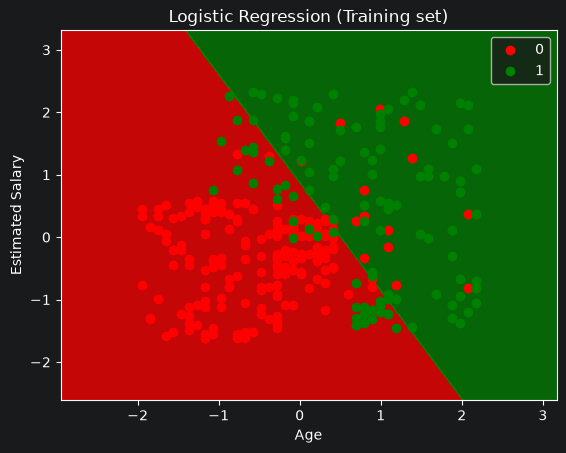

In [23]:
X_Set, y_Set = X_train, y_train

X1, X2 = np.meshgrid(
    np.arange(start=X_Set[:, 0].min() - 1, stop= X_Set[:, 0].max() + 1, step=0.01),
    np.arange(start=X_Set[:, 1].min() - 1, stop= X_Set[:, 1].max() + 1, step=0.01),
)

plt.contourf(
    X1, X2,
    classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
    alpha = 0.75,
    cmap = ListedColormap(("red", "green"))
)

plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_Set)):
    plt.scatter(
        X_Set[y_Set == j, 0],
        X_Set[y_Set == j, 1],
        label = j,
        color = ListedColormap(("red", "green"))(i),
    )
plt.title("Logistic Regression (Training set)")
plt.xlabel("Age")
plt.ylabel("Estimated Salary")
plt.legend()
plt.show()

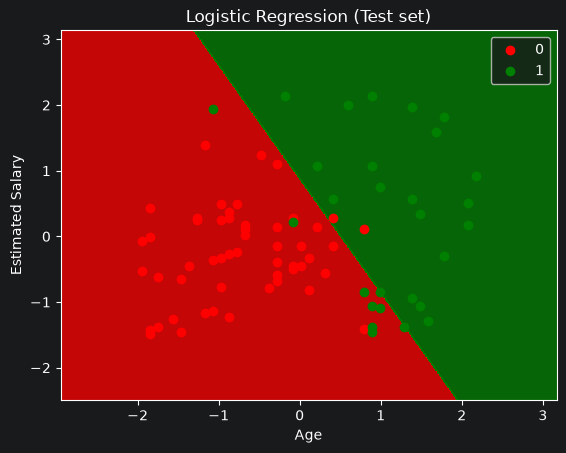

In [24]:
X_Set, y_Set = X_test, y_test

X1, X2 = np.meshgrid(
    np.arange(start=X_Set[:, 0].min() - 1, stop= X_Set[:, 0].max() + 1, step=0.01),
    np.arange(start=X_Set[:, 1].min() - 1, stop= X_Set[:, 1].max() + 1, step=0.01),
)

plt.contourf(
    X1, X2,
    classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
    alpha = 0.75,
    cmap = ListedColormap(("red", "green"))
)

plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_Set)):
    plt.scatter(
        X_Set[y_Set == j, 0],
        X_Set[y_Set == j, 1],
        label = j,
        color = ListedColormap(("red", "green"))(i),
    )
plt.title("Logistic Regression (Test set)")
plt.xlabel("Age")
plt.ylabel("Estimated Salary")
plt.legend()
plt.show()